In [ ]:
import os
import sys

sys.path.insert(0, "..")
sys.path.insert(0, "../..")
import random
import string
import time

import matplotlib.pyplot as plt
import torch

import ecoscape_connectivity
from ecoscape_connectivity import draw_layer, half_cauchy

In [2]:
import numpy as np

In [3]:
device = (
    torch.device("cuda")
    if torch.cuda.is_available()
    else torch.device("mps")
    if torch.backends.mps.is_available()
    else torch.device("cpu")
)

In [4]:
DATA_PATH = "../assets"

HABITAT_PATH = os.path.join(DATA_PATH, "habitat_CA.tif")
LANDCOVER_PATH = os.path.join(DATA_PATH, "terrain_CA.tif")
PERMEABILITY_PATH = os.path.join(DATA_PATH, "permeability_CA.csv")

In [5]:
permeability_table = ecoscape_connectivity.read_transmission_csv(PERMEABILITY_PATH)

CONNECTIVITY_PATH = os.path.join(DATA_PATH, "Outputs/connectivity_CA.tif")
FLOW_PATH = os.path.join(DATA_PATH, "Outputs/flow_CA.tif")

## Experiment

In [6]:
titles = {
    "connectivity_and_flow": "Standard Algorithm",
}

## Standard Algorithm lwksa

Time: 47.085789918899536
(289, 333)


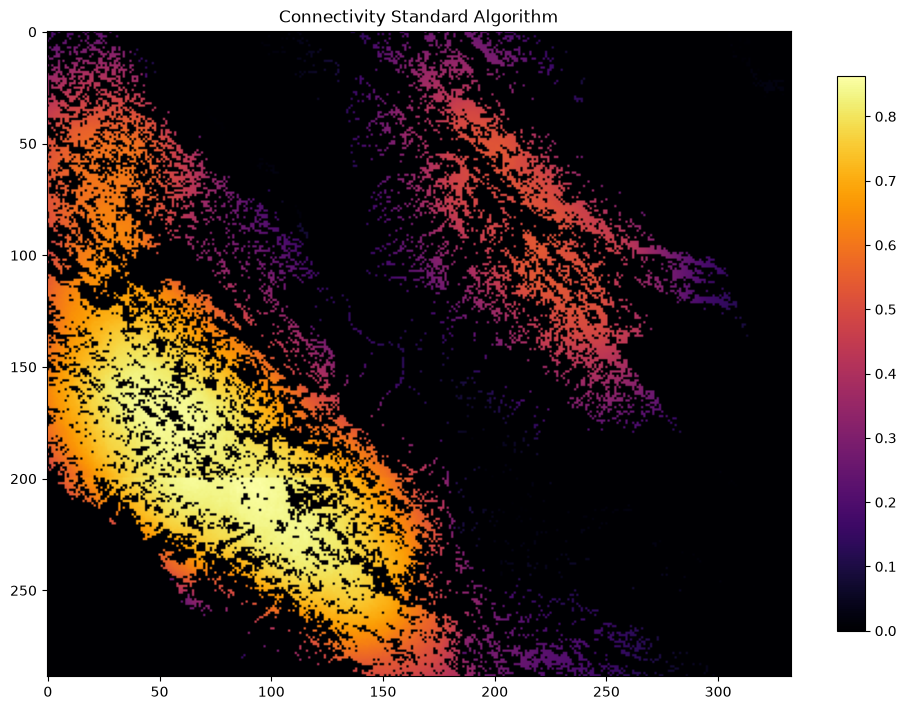

(289, 333)


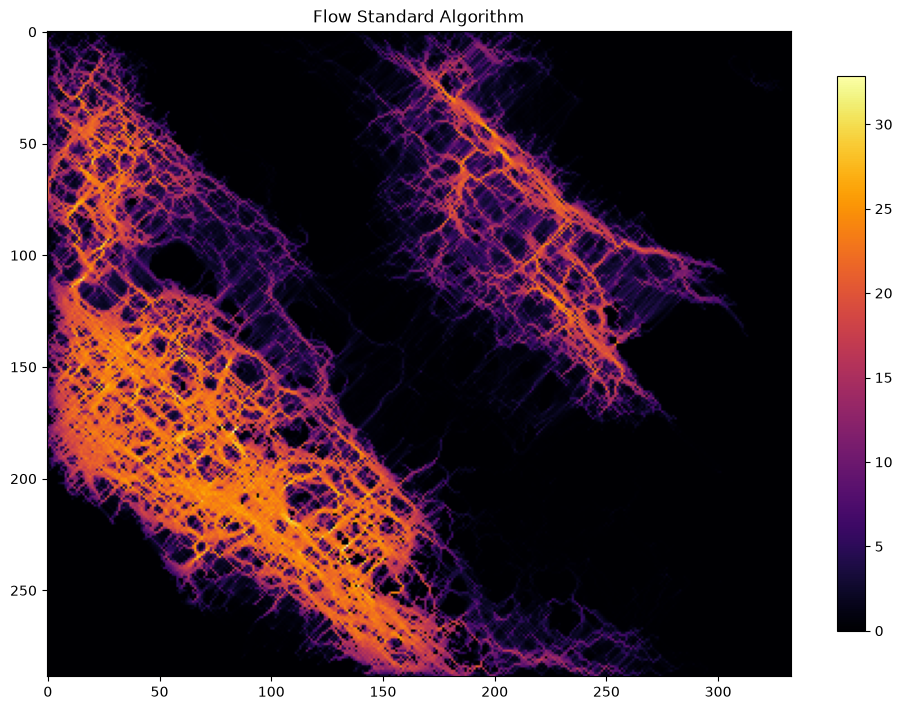

In [7]:
from IPython.display import Markdown, display

algos = [
    "connectivity_and_flow",
]

experiment = "".join(random.sample(string.ascii_lowercase, 5))
for algo in algos:
    display(Markdown(f"## {titles[algo]} {experiment}"))
    t0 = time.time()
    alg = getattr(ecoscape_connectivity, algo)
    alg(
        habitat_layer=HABITAT_PATH,
        landcover_layer=LANDCOVER_PATH,
        permeability_table=permeability_table,
        connectivity_layer=CONNECTIVITY_PATH,
        flow_layer=FLOW_PATH,
        tile_size=200,
        border_size=50,
        padding_size=50,
        batch_size=20,
        num_simulations=1000,
        dispersal_distance=50,
    )
    print("Time:", time.time() - t0)
    draw_layer(CONNECTIVITY_PATH, f"Connectivity {titles[algo]}", size=12)
    draw_layer(FLOW_PATH, f"Flow {titles[algo]}", size=12)

## Standard Algorithm yrwkl Half Cauchy

Time: 22.669788122177124
(289, 333)


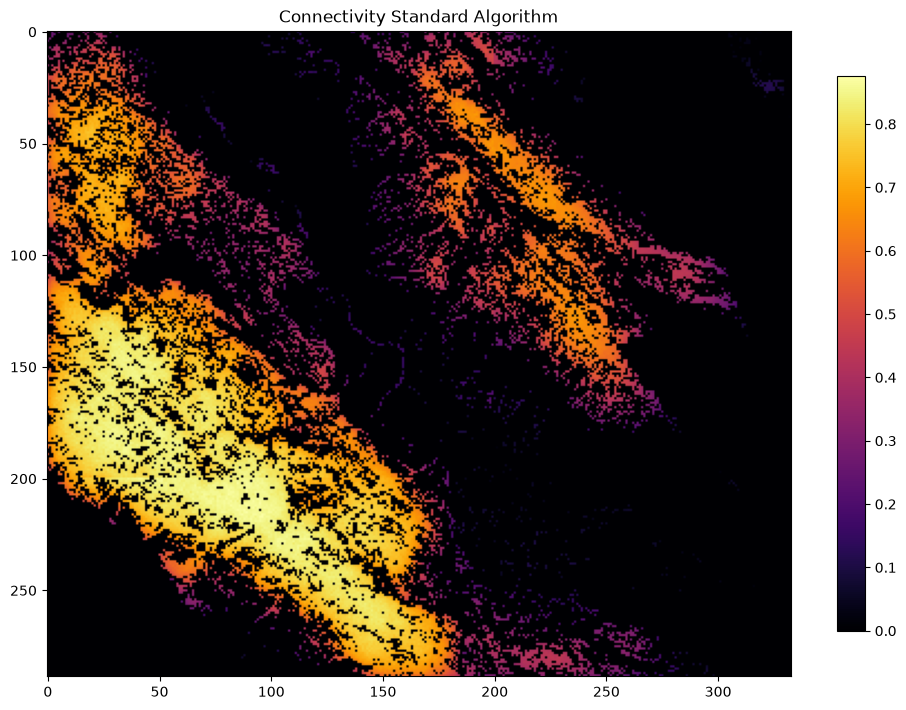

(289, 333)


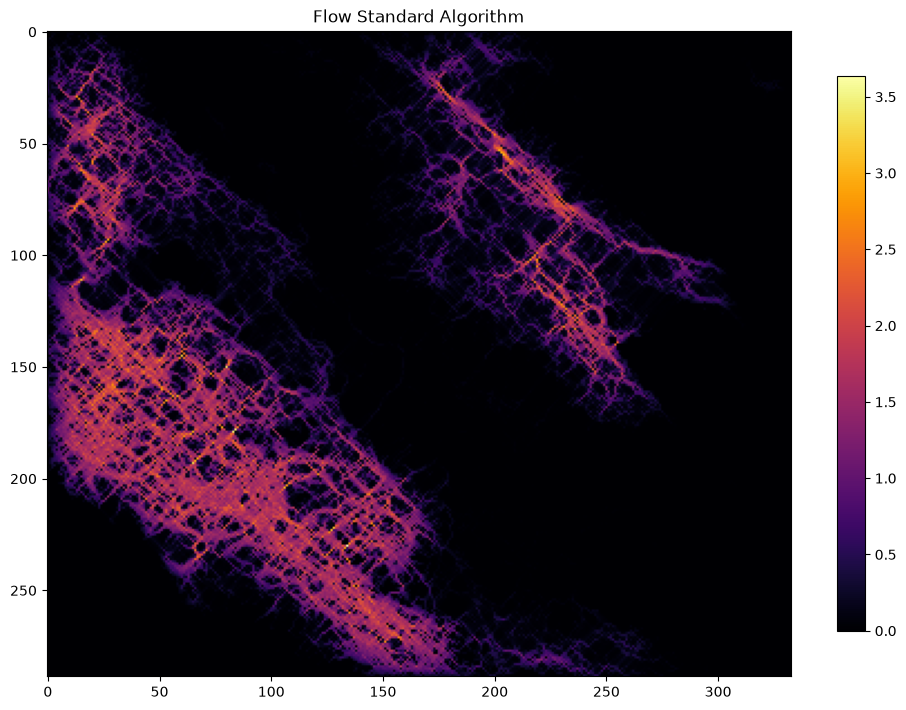

In [8]:
from IPython.display import Markdown, display

algos = [
    "connectivity_and_flow",
]

experiment = "".join(random.sample(string.ascii_lowercase, 5))
for algo in algos:
    display(Markdown(f"## {titles[algo]} {experiment} Half Cauchy"))
    t0 = time.time()
    alg = getattr(ecoscape_connectivity, algo)
    alg(
        habitat_layer=HABITAT_PATH,
        landcover_layer=LANDCOVER_PATH,
        permeability_table=permeability_table,
        connectivity_layer=CONNECTIVITY_PATH,
        flow_layer=FLOW_PATH,
        tile_size=200,
        border_size=50,
        padding_size=50,
        batch_size=20,
        num_simulations=1000,
        dispersal_distance=half_cauchy(20, 50),
    )
    print("Time:", time.time() - t0)
    draw_layer(CONNECTIVITY_PATH, f"Connectivity {titles[algo]}", size=12)
    draw_layer(FLOW_PATH, f"Flow {titles[algo]}", size=12)

## Ball

This is using coin tosses. 

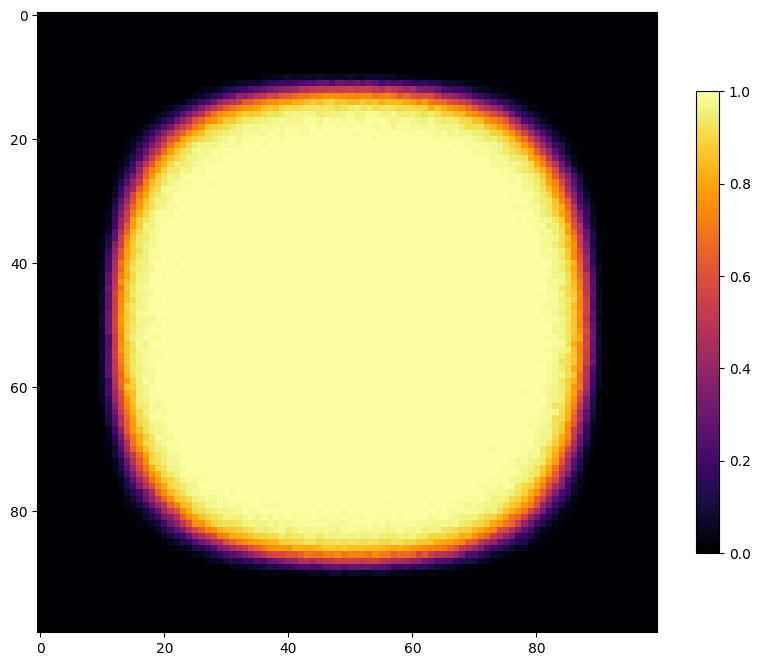

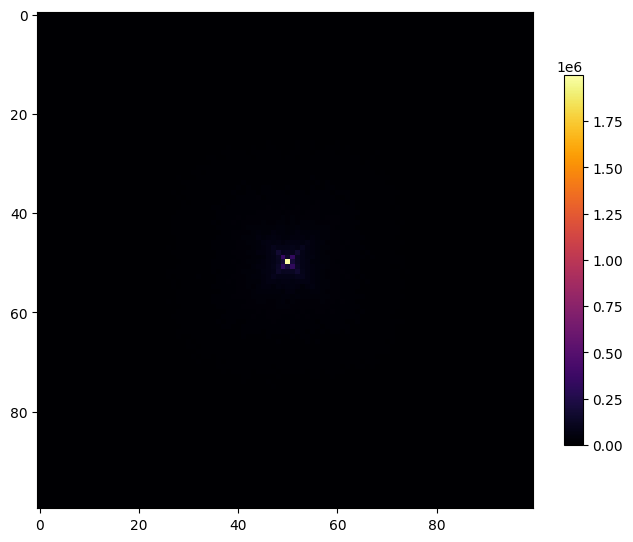

In [10]:
hab = torch.ones((100, 100), device=device)
ter = hab  # torch.zeros((100, 100), device=device)
repopulator = ecoscape_connectivity.RandomPropagate(
    hab, ter, num_spreads=40, spread_size=1, device=device
).to(device)
seeds = torch.zeros((400, 100, 100))
seeds[:, 50, 50] = 1
seeds = seeds.to(device)
pop = repopulator(seeds)
a = pop.cpu().detach().numpy()
a = np.mean(a, 0)
plt.figure(figsize=(10, 10))
plt.imshow(a, cmap="inferno")
plt.colorbar(shrink=0.6)
plt.show()
tot_pop = pop.sum()
tot_pop.backward()
flow = repopulator.get_grad()
flow = flow.cpu().detach().numpy()
plt.figure(figsize=(8, 8))
plt.imshow(flow, cmap="inferno")
plt.colorbar(shrink=0.6)
plt.show()

This is without using coin tosses. 

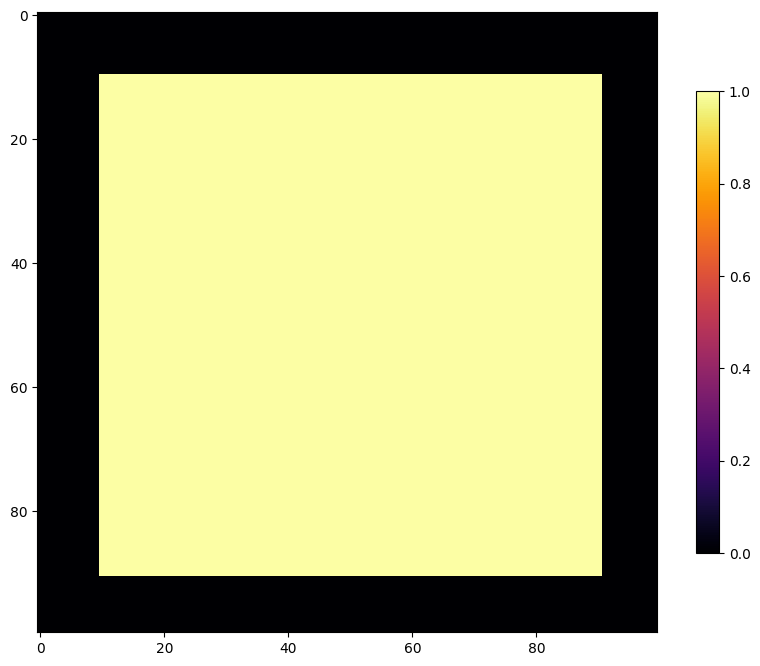

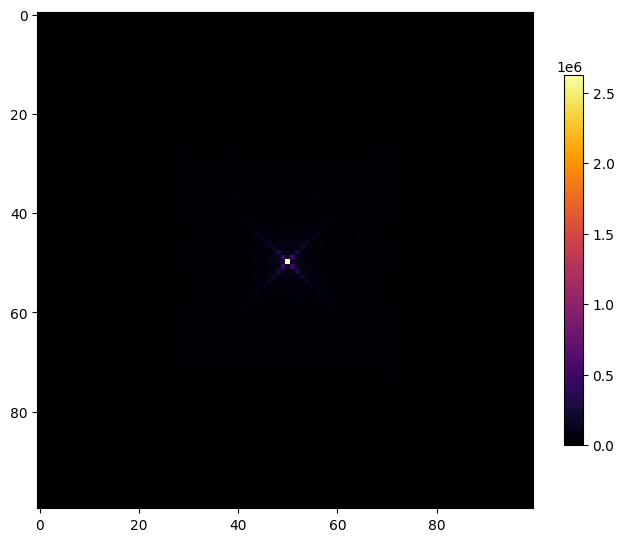

In [12]:
hab = torch.ones((100, 100), device=device)
ter = hab  # torch.zeros((100, 100), device=device)
repopulator = ecoscape_connectivity.RandomPropagate(
    hab, ter, num_spreads=40, coin_toss_probability=0.0, spread_size=1, device=device
).to(device)
seeds = torch.zeros((400, 100, 100))
seeds[:, 50, 50] = 1
seeds = seeds.to(device)
pop = repopulator(seeds)
a = pop.cpu().detach().numpy()
a = np.mean(a, 0)
plt.figure(figsize=(10, 10))
plt.imshow(a, cmap="inferno")
plt.colorbar(shrink=0.6)
plt.show()
tot_pop = pop.sum()
tot_pop.backward()
flow = repopulator.get_grad()
flow = flow.cpu().detach().numpy()
plt.figure(figsize=(8, 8))
plt.imshow(flow, cmap="inferno")
plt.colorbar(shrink=0.6)
plt.show()